# v2 checks (2026-11-19)

Checks on the v2-sweep (`-rand16`) models: v2 data (`_p5_n10000` × `_biasnoisenestv2_p9_n320000` × `_noisefly`), noise in θ, sweeps at kp0.37 / kpgm0.24 / kb0.24. Continues from `2026-11-16_planning_for_v2.ipynb` (sections 1–5 there used the interim v1-hyperparameter models). Each section runs on its own after the setup cell.

1. Sweep validation losses
2. Ensembling: top-3 hyperparameter settings vs 3 seeds of the top setting
3. k_max grid: SHAMe figure of bias vs k_max^{P_gm} and k_max^B
4. Prior leakage: posterior samples outside the physical prior box
5. Paper Fig 7, top model only: SHAMe vs phase-matched mock across n̄

In [1]:
import os
import sys
import re
import glob
import ast
from pathlib import Path

os.environ["MUCHISIMOCKS_DATA"] = "/scratch/kstoreyf/muchisimocks/data_v2"
os.environ["MUCHISIMOCKS_RESULTS"] = "/scratch/kstoreyf/muchisimocks/results_v2"

REPO_ROOT = Path.cwd()
if REPO_ROOT.name == "notebooks":
    REPO_ROOT = REPO_ROOT.parent
sys.path.insert(0, str(REPO_ROOT / "code"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

import data_loader
import plotter
import paths

%load_ext autoreload
%autoreload 2

DIR_SBI = Path(paths.DIR_RESULTS) / "results_sbi"
FIG_DIR = REPO_ROOT / "figures" / "2026-11-19_v2_checks"
FIG_DIR.mkdir(parents=True, exist_ok=True)
print("results:", paths.DIR_RESULTS)

results: /scratch/kstoreyf/muchisimocks/results_v2


## 1. v2 hyperparameter sweeps: sorted best validation loss

One panel per statistics combination (`-rand16` sweeps at kp0.37 / kpgm0.24 / kb0.24, noise in θ). Each point is one trial's best validation loss (NLL, lower is better), sorted, so a clear gap after the first few trials shows whether there is a distinct top group. Open points are trials still training, plotted at their current best. Orange diamonds at rank 1 are the rank-1 hyperparameters retrained with other seeds (seeds 1 and 2; the rank-1 point is seed 0), which show how much of the spread between trials is seed noise. The dotted line marks the top 3 (`choose_best_run.py --n-passing 3` keeps the top 3 trials that also pass the coverage and SHAMe checks). Losses can only be compared within a panel, since each combination has a different data vector.

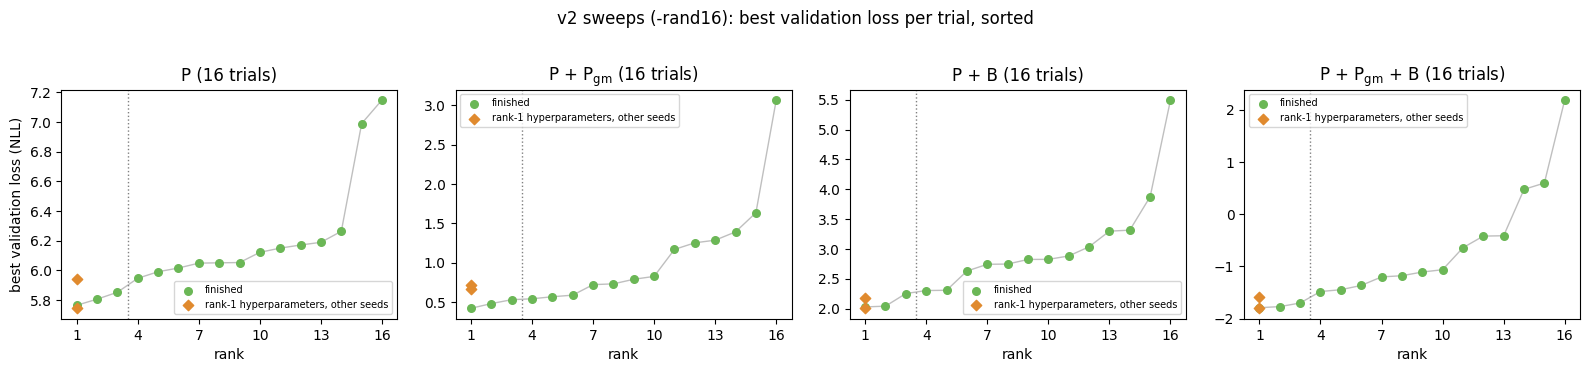

P | gap rank1→2, 2→3, 3→4: [0.041 0.047 0.094]
        run  best_val_loss  n_epochs  done  hidden_features  num_transforms  learning_rate  training_batch_size
0  qfkv8ilf         5.7638       144  True              512              10         0.0001                  256
1  zs7d4tzi         5.8049       187  True              512               6         0.0001                  256
2  7jvggbd5         5.8516        95  True              512               6         0.0001                   64
3  ywy0pk5u         5.9458        92  True              512              10         0.0003                  256
4  q2eg13gi         5.9901       262  True              128              10         0.0001                  256
5  86i1xnv3         6.0151       207  True              256              10         0.0000                   64
rank-1 hyperparameters, other seeds:
 seed  best_val_loss  n_epochs  done
    1         5.9444       134  True
    2         5.7434       143  True

P + P$_{\rm gm}$ | g

In [2]:
# best validation loss per v2 sweep trial, parsed from the sweep logs (the inference.p files are ~70 MB each).
# Each array task trains one trial; its log has the W&B run id and the chunked-training lines
# "epoch N: val loss X (best Y, ...)". Requeued tasks append to the same log, so the last "best" is the trial's best.
LOG_DIR_V2 = "/scratch/kstoreyf/muchisimocks/logs_v2"
SWEEPS = {   # label: (log job name, sweep results dir)
    "P": ("sweep_v2_pk", "sbi_muchisimocks_pk_kp0.37"),
    "P + P$_{\\rm gm}$": ("sweep_v2_pk_pgm", "sbi_muchisimocks_pk_pgm_kp0.37_kpgm0.24"),
    "P + B": ("sweep_v2_pk_bispec", "sbi_muchisimocks_pk_bispec_kp0.37_kb0.24"),
    "P + P$_{\\rm gm}$ + B": ("sweep_v2_pk_pgm_bispec", "sbi_muchisimocks_pk_pgm_bispec_kp0.37_kpgm0.24_kb0.24"),
}
# extra seeds of each sweep's best run (best_runs.txt line 0; seed 0 is the rank-1 trial itself), trained by
# job_train_v2.s with lists from code_auxiliary/make_best_seeds_list_v2.py; logs train_v2_bestseeds_<stats>-<job>_<task>.out
SEED_JOBS = {lab: "train_v2_bestseeds_" + job[len("sweep_v2_"):] for lab, (job, _) in SWEEPS.items()}
HP_KEYS = ["hidden_features", "num_transforms", "learning_rate", "training_batch_size"]

def sweep_trials(job, prefix):
    dir_sweep = glob.glob(str(DIR_SBI / f"{prefix}_p5_n10000_*_sweep-rand16"))
    assert len(dir_sweep) == 1, dir_sweep
    dir_sweep = Path(dir_sweep[0])
    rows = []
    for f in sorted(glob.glob(f"{LOG_DIR_V2}/{job}_[0-9]*_[0-9]*.out")):
        t = open(f, errors="ignore").read().replace("\r", "\n")
        rid = re.findall(r"run-\d{8}_\d{6}-([a-z0-9]{8})", t)
        best = re.findall(r"epoch (\d+): val loss \S+ \(best (\S+),", t)
        if not rid or not best:
            continue
        rid = rid[-1]
        hp = re.findall(r"^wandb\.config: (\{.*\})$", t, re.M)
        hp = ast.literal_eval(hp[-1]) if hp else {}
        rows.append({"run": rid, "best_val_loss": float(best[-1][1]), "n_epochs": int(best[-1][0]),
                     "done": (dir_sweep / rid / "posterior.p").is_file(), **{k: hp.get(k) for k in HP_KEYS}})
    return pd.DataFrame(rows).drop_duplicates("run", keep="last").sort_values("best_val_loss").reset_index(drop=True)

def seed_trials(job):
    """Best validation loss of the retrained seeds (>= 1); the newest log per seed wins (reruns append/new jobs)."""
    rows = {}
    for f in sorted(glob.glob(f"{LOG_DIR_V2}/{job}-[0-9]*_[0-9]*.out"), key=os.path.getmtime):
        t = open(f, errors="ignore").read().replace("\r", "\n")
        seed = re.findall(r"^train: \S*_best-rand16_seed(\d+)\.yaml", t, re.M)
        best = re.findall(r"epoch (\d+): val loss \S+ \(best (\S+),", t)
        if seed and best:
            rows[int(seed[-1])] = {"seed": int(seed[-1]), "best_val_loss": float(best[-1][1]),
                                   "n_epochs": int(best[-1][0]), "done": "Saved model to" in t}
    return pd.DataFrame(rows.values(), columns=["seed", "best_val_loss", "n_epochs", "done"]).sort_values("seed")

df_sweeps = {lab: sweep_trials(*v) for lab, v in SWEEPS.items()}
df_seeds = {lab: seed_trials(SEED_JOBS[lab]) for lab in SWEEPS}

fig, axes = plt.subplots(1, len(df_sweeps), figsize=(4 * len(df_sweeps), 3.6))
for ax, (lab, d) in zip(axes, df_sweeps.items()):
    rank = np.arange(1, len(d) + 1)
    ax.plot(rank, d["best_val_loss"], "-", color="0.75", lw=1, zorder=1)
    ax.scatter(rank[d["done"]], d["best_val_loss"][d["done"]], color="#6BB756", s=30, zorder=2, label="finished")
    if (~d["done"]).any():
        ax.scatter(rank[~d["done"]], d["best_val_loss"][~d["done"]], facecolor="none", edgecolor="#1F2F6B",
                   s=30, zorder=2, label="still training")
    ds = df_seeds[lab]   # extra seeds of the rank-1 hyperparameters, drawn at rank 1
    if len(ds):
        done = ds["done"].values
        ax.scatter(np.ones(done.sum()), ds["best_val_loss"][done], marker="D", color="#E08A2E", s=28, zorder=3,
                   label="rank-1 hyperparameters, other seeds")
        if (~done).any():
            ax.scatter(np.ones((~done).sum()), ds["best_val_loss"][~done], marker="D", facecolor="none",
                       edgecolor="#E08A2E", s=28, zorder=3, label="other seed, still training")
    if (~d["done"]).any() or len(ds):
        ax.legend(fontsize=7)
    ax.axvline(3.5, color="0.5", ls=":", lw=1)   # choose_best_run keeps the top 3 that pass the checks
    ax.set_title(f"{lab} ({len(d)} trials)")
    ax.set_xlabel("rank")
    ax.set_xticks(rank[::3])
axes[0].set_ylabel("best validation loss (NLL)")
fig.suptitle("v2 sweeps (-rand16): best validation loss per trial, sorted", y=1.02)
fig.tight_layout()
fig.savefig(FIG_DIR / "sweep_v2_best_val_loss_sorted.pdf", bbox_inches="tight")
plt.show()

for lab, d in df_sweeps.items():
    print(lab, "| gap rank1→2, 2→3, 3→4:", np.round(np.diff(d["best_val_loss"].values[:4]), 3))
    print(d.head(6).round(4).to_string())
    if len(df_seeds[lab]):
        print("rank-1 hyperparameters, other seeds:\n" + df_seeds[lab].round(4).to_string(index=False))
    print()


## 2. Ensembling the v2 models: top-3 hyperparameter settings vs 3 seeds of the top setting

`-rand16` sweep models at the fiducial cuts (kp0.37 / kpgm0.24 / kb0.24, noise in θ), for every statistics combination. We compare two equal-weight posterior mixtures:
- **top-3 settings:** best_runs.txt lines 0–2 of the sweep, seed 0 each (`best-rand16`, `_nbest1`, `_nbest2`);
- **3 seeds:** the top setting retrained with seeds 0, 1 and 2 (`best-rand16`, `_seed1`, `_seed2`).

Both mixtures share the top-setting seed-0 network. Coverage uses the full `inner500` subset of the v2 coverage set (the 500 rows farthest from the prior edges in Ω_c, σ8 and b1). The top setting, seed 0 is run on all 1000 rows (for paper Figs 4/5), and we take its inner500 rows here. Tests come from `code_auxiliary/make_ensemble_tests_rand16.py`. A model whose test is still running is plotted from its partial samples (`_pred_inprogress.npy`, finished rows only), with n in the legend. This section runs on its own after the first setup cell.


In [3]:
# §2 setup: rand16 models, loaders and P-P helpers
import utils_inference
import plotter_figs

DIR_SBI = Path(paths.DIR_RESULTS) / "results_sbi"
R16_COMBOS = {   # label: (stats tag as in the sweep dir, masks)
    "P": ("pk", "_kp0.37"),
    "P + P$_{\\rm gm}$": ("pk_pgm", "_kp0.37_kpgm0.24"),
    "P + B": ("pk_bispec", "_kp0.37_kb0.24"),
    "P + P$_{\\rm gm}$ + B": ("pk_pgm_bispec", "_kp0.37_kpgm0.24_kb0.24"),
}
R16_COLORS = dict(zip(R16_COMBOS, plotter_figs.COLORS_FID))   # paper color per combo (filled = 3 seeds)
COLOR_TOP3 = "#1F2F6B"                                          # navy (outlines) = top-3 settings
R16_MEMBERS = {"top-3 settings": ["", "_nbest1", "_nbest2"], "3 seeds": ["", "_seed1", "_seed2"]}
KEY3 = ["omega_cold", "sigma8_cold", "b1"]
KEY3_LABELS = {"omega_cold": r"$\Omega_{\rm c}$", "sigma8_cold": r"$\sigma_8$", "b1": r"$b_1$"}
TAG_COV16 = "_coveragev2_p5_n1000_biasnoisecoveragev2_p9_n1000_noisefly"
SUB16 = "inner500"

def r16_dir(stats, masks, member):
    return DIR_SBI / f"sbi_muchisimocks_{stats}{masks}_p5_n10000_biasnoisenestv2_p9_n320000_noisefly_rp_bx32_ntrain10000_best-rand16{member}"

def to_key3(s, names):
    # (..., n_params) reparameterized samples -> (..., 3) physical (Ω_c, σ8, b1)
    s, names = utils_inference.unreparameterize_theta(np.asarray(s, dtype=np.float64), list(names), strict=False)
    names = list(names)
    return s[..., [names.index(k) for k in KEY3]]

idxs16 = np.load(REPO_ROOT / "data" / "params" / f"idxs_obs_coveragev2_p5_n1000_{SUB16}.npy")
_cos16 = pd.read_csv(REPO_ROOT / "data" / "params" / "params_lh_coveragev2_p5_n1000.txt", index_col=0)
_bia16 = pd.read_csv(REPO_ROOT / "data" / "params" / "params_lh_biasnoisecoveragev2_p9_n1000.txt", index_col=0)
truth16 = np.stack([_cos16.loc[idxs16, "omega_cold"], _cos16.loc[idxs16, "sigma8_cold"], _bia16.loc[idxs16, "b1"]], axis=1)

def load_cov16(stats, masks, member):
    # (n_samples, 500, 3) physical; unfinished rows are NaN. Returns (samples, "done"/"inprogress") or (None, None).
    # The top setting, seed 0 (member "") runs the full 1000-row coverage set; its inner500 rows are taken from it.
    d = r16_dir(stats, masks, member)
    base = f"samples_test_muchisimocks_{stats}{masks}{TAG_COV16}" + ("" if member == "" else f"_{SUB16}")
    for suffix, kind in (("_pred.npy", "done"), ("_pred_inprogress.npy", "inprogress")):
        f = d / (base + suffix)
        if f.exists():
            s = np.load(f, mmap_mode="r")
            if member == "":
                assert s.shape[1] == len(_cos16), (f, s.shape)
                s = s[:, idxs16]
            s = to_key3(s, np.loadtxt(d / "param_names.txt", dtype=str))
            assert s.shape[1] == len(idxs16), (f, s.shape)
            return s, kind
    return None, None

def mix16(arrs, seed=0):
    # equal-weight mixture over the first axis (works for (n, n_obs, 3) and (n, 3))
    rng = np.random.default_rng(seed)
    n = min(a.shape[0] for a in arrs) // len(arrs)
    return np.concatenate([a[rng.choice(a.shape[0], n, replace=False)] for a in arrs], axis=0)

CRED16 = np.linspace(0, 1, 51)
def pp16(s):
    # P-P curves (3, n_levels) over rows finished in s, and the number of rows used
    ok = np.isfinite(s).all(axis=(0, 2))
    ranks = (s[:, ok, :] < truth16[ok][None]).mean(axis=0)
    a = 2 * np.abs(ranks - 0.5)
    return np.stack([(a[:, j][:, None] <= CRED16[None]).mean(axis=0) for j in range(3)]), ok.sum()

cov16 = {(lab, m): load_cov16(st, mk, m) for lab, (st, mk) in R16_COMBOS.items()
         for m in sorted(set(sum(R16_MEMBERS.values(), [])))}
for (lab, m), (s, kind) in cov16.items():
    n = None if s is None else int(np.isfinite(s).all(axis=(0, 2)).sum())
    print(f"{lab:24s} {('top' + m) if m else 'top seed0':12s} {kind or 'missing'} {'' if n is None else f'({n}/500 rows)'}")


2026-11-20 07:42:03.883252: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-11-20 07:42:03.928463: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-11-20 07:42:04.043522: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-11-20 07:42:04.043580: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-11-20 07:42:04.060198: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to

2026-11-20 07:42:05.776046: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT


P                        top seed0    inprogress (222/500 rows)
P                        top_nbest1   done (500/500 rows)
P                        top_nbest2   done (500/500 rows)
P                        top_seed1    done (500/500 rows)
P                        top_seed2    done (500/500 rows)
P + P$_{\rm gm}$         top seed0    inprogress (474/500 rows)
P + P$_{\rm gm}$         top_nbest1   done (500/500 rows)
P + P$_{\rm gm}$         top_nbest2   done (500/500 rows)
P + P$_{\rm gm}$         top_seed1    done (500/500 rows)
P + P$_{\rm gm}$         top_seed2    done (500/500 rows)
P + B                    top seed0    done (500/500 rows)


P + B                    top_nbest1   done (500/500 rows)
P + B                    top_nbest2   done (500/500 rows)
P + B                    top_seed1    done (500/500 rows)
P + B                    top_seed2    done (500/500 rows)
P + P$_{\rm gm}$ + B     top seed0    inprogress (178/500 rows)
P + P$_{\rm gm}$ + B     top_nbest1   done (500/500 rows)
P + P$_{\rm gm}$ + B     top_nbest2   done (500/500 rows)
P + P$_{\rm gm}$ + B     top_seed1    inprogress (360/500 rows)
P + P$_{\rm gm}$ + B     top_seed2    inprogress (475/500 rows)


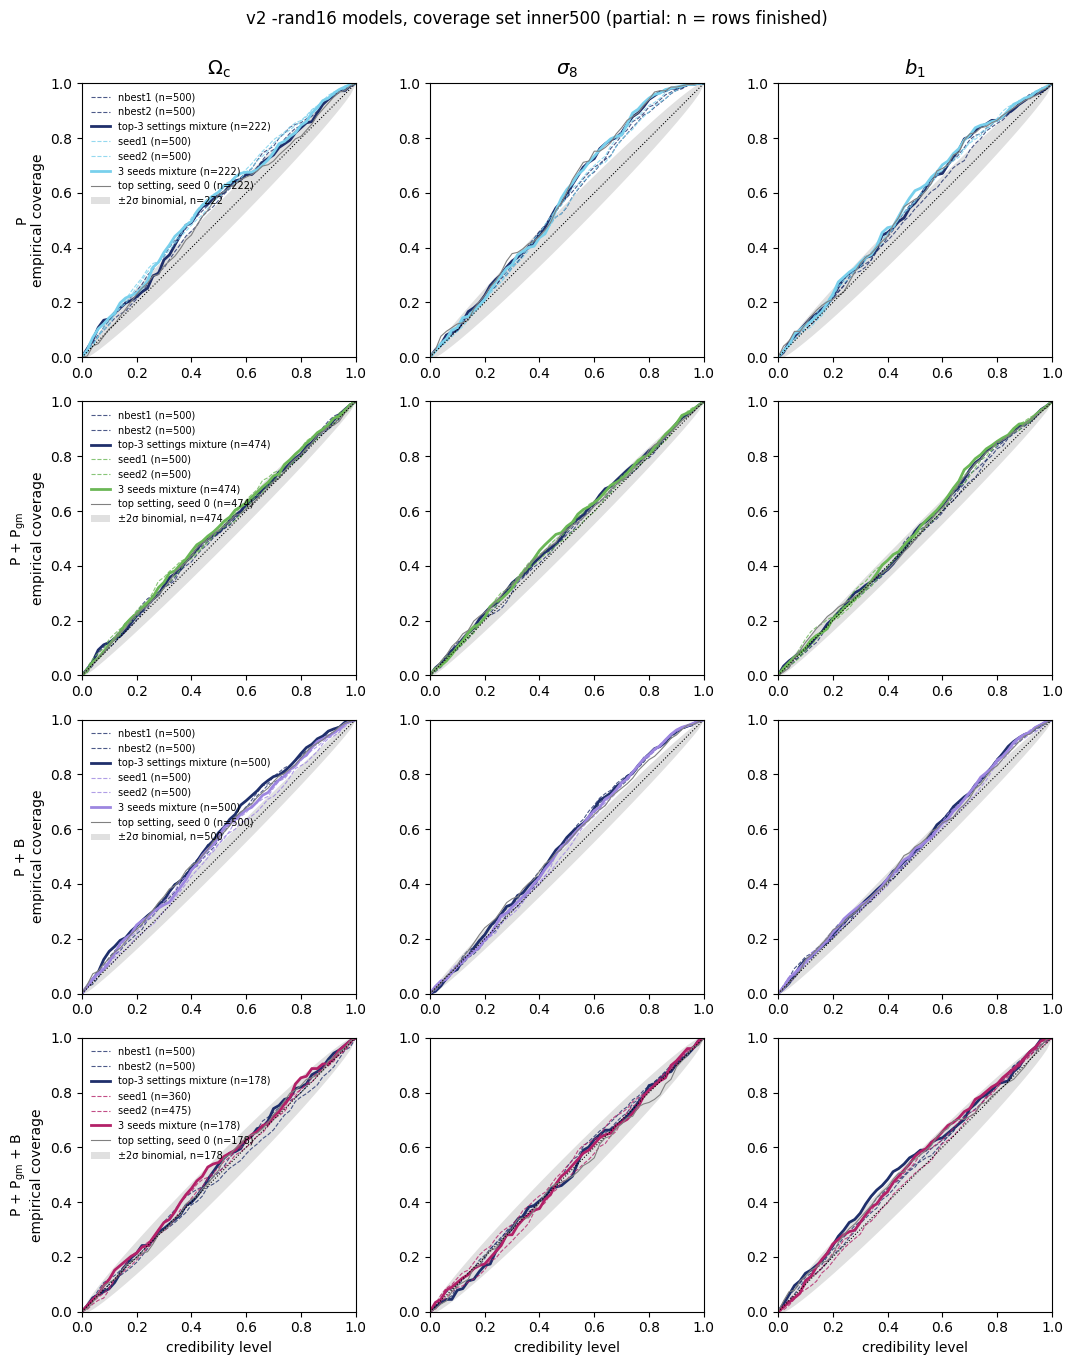

In [4]:
fig, axes = plt.subplots(len(R16_COMBOS), 3, figsize=(11, 3.4 * len(R16_COMBOS)), squeeze=False)
n_mix = {lab: [] for lab in R16_COMBOS}   # rows used per mixture
n_ind = {lab: [] for lab in R16_COMBOS}   # rows per individual network
for r, lab in enumerate(R16_COMBOS):
    for ens, members in R16_MEMBERS.items():
        color = COLOR_TOP3 if ens == "top-3 settings" else R16_COLORS[lab]
        arrs = [cov16[(lab, m)][0] for m in members]
        for m, a in zip(members, arrs):          # individual networks, thin
            if a is None or m == "":             # seed-0 top network is drawn once, in grey
                continue
            pp, n = pp16(a)
            n_ind[lab].append(n)
            for c in range(3):
                axes[r, c].plot(CRED16, pp[c], color=color, lw=0.8, ls="--", alpha=0.8,
                                label=f"{m.strip('_')} (n={n})" if c == 0 else None)
        if all(a is not None for a in arrs):
            # mixtures use only rows finished in all three members
            ok = np.all([np.isfinite(a).all(axis=(0, 2)) for a in arrs], axis=0)
            pp, n = pp16(mix16([np.where(ok[None, :, None], a, np.nan) for a in arrs]))
            n_mix[lab].append(n)
            for c in range(3):
                axes[r, c].plot(CRED16, pp[c], color=color, lw=2.0, label=f"{ens} mixture (n={n})" if c == 0 else None)
    a0 = cov16[(lab, "")][0]
    if a0 is not None:
        pp, n = pp16(a0)
        n_ind[lab].append(n)
        for c in range(3):
            axes[r, c].plot(CRED16, pp[c], color="0.5", lw=0.8, label=f"top setting, seed 0 (n={n})" if c == 0 else None)
    # ±2σ binomial band for the mixtures' row count (the smaller one); if no mixture yet, for the fewest rows plotted
    n_band = min(n_mix[lab]) if n_mix[lab] else min(n_ind[lab], default=0)
    band = 2 * np.sqrt(CRED16 * (1 - CRED16) / max(n_band, 1))
    for c, p in enumerate(KEY3):
        ax = axes[r, c]
        if n_band:
            ax.fill_between(CRED16, CRED16 - band, CRED16 + band, color="0.88", lw=0,
                            label=f"±2σ binomial, n={n_band}" if c == 0 else None)
        ax.plot([0, 1], [0, 1], "k:", lw=0.8)
        ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal")
        if r == 0:
            ax.set_title(KEY3_LABELS[p], fontsize=14)
        if r == len(R16_COMBOS) - 1:
            ax.set_xlabel("credibility level")
    axes[r, 0].set_ylabel(f"{lab}\nempirical coverage", fontsize=10)
    axes[r, 0].legend(fontsize=7, loc="upper left", frameon=False)
fig.suptitle(f"v2 -rand16 models, coverage set {SUB16} (partial: n = rows finished)", y=1.0)
fig.tight_layout()
fig.savefig(FIG_DIR / f"coverage_pp_rand16_ensembles_{SUB16}.pdf", bbox_inches="tight")
plt.show()


In [5]:
# Per network and per mixture: mean (coverage − credibility) over levels (+ = conservative, − = overconfident),
# coverage of the central 68% / 95% intervals, median posterior σ
rows16 = []
def summarize16(combo, model, s):
    pp, n = pp16(s)
    row = {"combo": combo, "model": model, "n": n}
    for c, p in enumerate(KEY3):
        row[(p, "mean Δ")] = (pp[c] - CRED16).mean()
        row[(p, "cov68")] = np.interp(0.68, CRED16, pp[c])
        row[(p, "cov95")] = np.interp(0.95, CRED16, pp[c])
        row[(p, "med σ")] = np.nanmedian(s[:, :, c].std(axis=0))
    rows16.append(row)
for lab in R16_COMBOS:
    for m in ["", "_seed1", "_seed2", "_nbest1", "_nbest2"]:
        s = cov16[(lab, m)][0]
        if s is not None:
            summarize16(lab, m.strip("_") or "top, seed0", s)
    for ens, members in R16_MEMBERS.items():
        arrs = [cov16[(lab, m)][0] for m in members]
        if all(a is not None for a in arrs):
            ok = np.all([np.isfinite(a).all(axis=(0, 2)) for a in arrs], axis=0)
            summarize16(lab, f"mixture: {ens}", mix16([np.where(ok[None, :, None], a, np.nan) for a in arrs]))
if rows16:
    df_cov16 = pd.DataFrame(rows16).set_index(["combo", "model"])
    df_cov16.columns = pd.MultiIndex.from_tuples([c if isinstance(c, tuple) else (c, "") for c in df_cov16.columns])
    print(f"±2σ binomial scatter at n=500: cov68 ≈ ±{2*np.sqrt(.68*.32/500):.3f}, cov95 ≈ ±{2*np.sqrt(.95*.05/500):.3f}")
    display(df_cov16.round(3))
else:
    print("no rand16 coverage samples yet")


±2σ binomial scatter at n=500: cov68 ≈ ±0.042, cov95 ≈ ±0.019


n omega_cold                \
                                                      mean Δ  cov68  cov95   
combo                model                                                   
P                    top, seed0               222      0.031  0.703  0.971   
                     seed1                    500      0.058  0.754  0.974   
                     seed2                    500      0.068  0.772  0.983   
                     nbest1                   500      0.041  0.746  0.974   
                     nbest2                   500      0.059  0.758  0.974   
                     mixture: top-3 settings  222      0.049  0.725  0.973   
                     mixture: 3 seeds         222      0.060  0.721  0.982   
P + P$_{\rm gm}$     top, seed0               474      0.014  0.686  0.943   
                     seed1                    500      0.015  0.694  0.949   
                     seed2                    500      0.029  0.722  0.965   
                     nbest1                   500      0.008  0.688  0.950   
                     nbest2                   500      0.018  0.690  0.962   
                     mixture: top-3 settings  474      0.019  0.696  0.961   
                     mixture: 3 seeds         474      0.027  0.705  0.957   
P + B                top, seed0               500      0.051  0.750  0.980   
                     seed1                    500      0.019  0.710  0.967   
                     seed2                    500      0.036  0.720  0.967   
                     nbest1                   500      0.049  0.766  0.978   
                     nbest2                   500      0.050  0.762  0.981   
                     mixture: top-3 settings  500      0.060  0.778  0.981   
                     mixture: 3 seeds         500      0.044  0.734  0.975   
P + P$_{\rm gm}$ + B top, seed0               178      0.010  0.691  0.955   
                     seed1                    360      0.002  0.678  0.949   
                     seed2                    475      0.013  0.695  0.945   
                     nbest1                   500     -0.015  0.646  0.939   
                     nbest2                   500      0.015  0.710  0.954   
                     mixture: top-3 settings  178      0.014  0.697  0.963   
                     mixture: 3 seeds         178      0.025  0.685  0.963   

                                                    sigma8_cold                \
                                              med σ      mean Δ  cov68  cov95   
combo                model                                                      
P                    top, seed0               0.028       0.077  0.815  0.995   
                     seed1                    0.030       0.061  0.796  0.995   
                     seed2                    0.031       0.046  0.770  0.995   
                     nbest1                   0.029       0.050  0.770  0.994   
                     nbest2                   0.030       0.057  0.784  0.994   
                     mixture: top-3 settings  0.029       0.072  0.802  0.995   
                     mixture: 3 seeds         0.029       0.071  0.806  0.995   
P + P$_{\rm gm}$     top, seed0               0.015       0.021  0.696  0.953   
                     seed1                    0.016       0.022  0.704  0.971   
                     seed2                    0.016       0.008  0.690  0.956   
                     nbest1                   0.016       0.013  0.704  0.956   
                     nbest2                   0.016       0.009  0.698  0.960   
                     mixture: top-3 settings  0.016       0.022  0.711  0.961   
                     mixture: 3 seeds         0.016       0.024  0.705  0.964   
P + B                top, seed0               0.026       0.038  0.734  0.981   
                     seed1                    0.024       0.030  0.742  0.980   
                     seed2                    0.025       0.026  0.732  0.979   
         

### 2b. SHAMe posteriors: top-3 settings vs 3 seeds

SHAMe high-fidelity mock at $\bar{n}=2.2\times10^{-4}$, for Ω_c, σ8 and physical b1. Each figure shows one statistics combination. The 3-seed mixture is filled, in the paper color for that combination. The top-3-settings mixture is drawn as navy outlines, with thin navy lines marking its 1D 68% interval. Black dashed lines mark the SHAMe truth.


SHAMe truth: {'sigma8_cold': 0.816, 'omega_cold': 0.309, 'b1': 0.474}


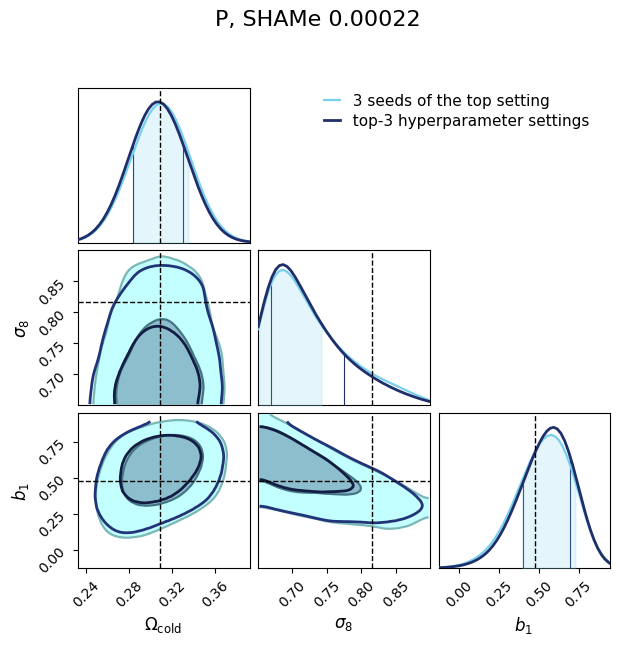

  3 seeds bias/σ: omega_cold=+0.01, sigma8_cold=-1.67, b1=+0.40 | σ: omega_cold=0.0230, sigma8_cold=0.0561, b1=0.1530
  top-3  bias/σ: omega_cold=-0.08, sigma8_cold=-1.83, b1=+0.50 | σ: omega_cold=0.0227, sigma8_cold=0.0533, b1=0.1466


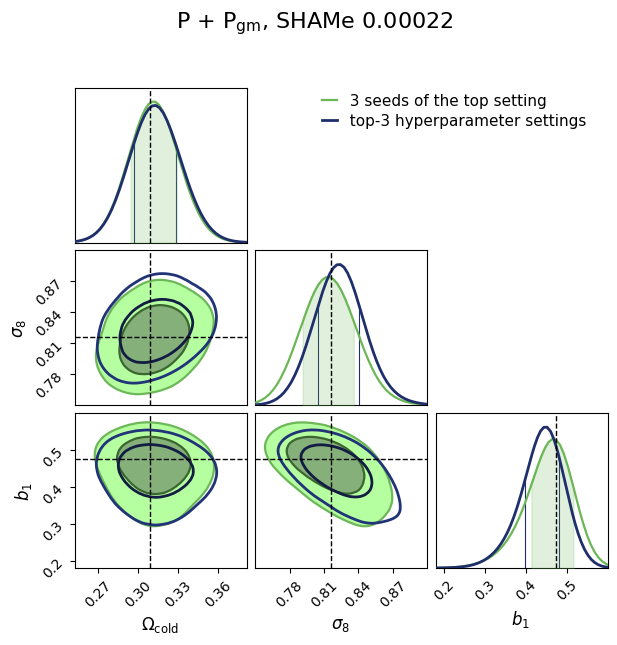

  3 seeds bias/σ: omega_cold=+0.21, sigma8_cold=-0.06, b1=-0.43 | σ: omega_cold=0.0156, sigma8_cold=0.0200, b1=0.0482
  top-3  bias/σ: omega_cold=+0.26, sigma8_cold=+0.40, b1=-0.80 | σ: omega_cold=0.0158, sigma8_cold=0.0188, b1=0.0442


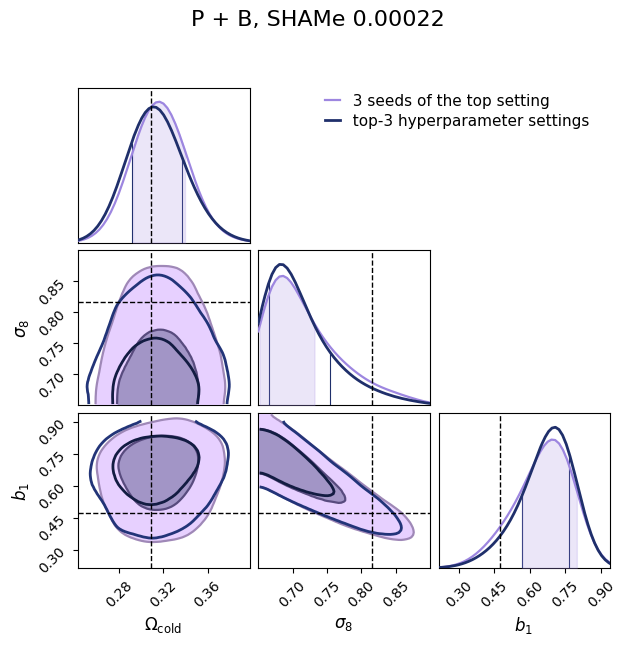

  3 seeds bias/σ: omega_cold=+0.37, sigma8_cold=-1.94, b1=+1.68 | σ: omega_cold=0.0215, sigma8_cold=0.0518, b1=0.1089
  top-3  bias/σ: omega_cold=+0.22, sigma8_cold=-2.26, b1=+1.89 | σ: omega_cold=0.0231, sigma8_cold=0.0474, b1=0.1031


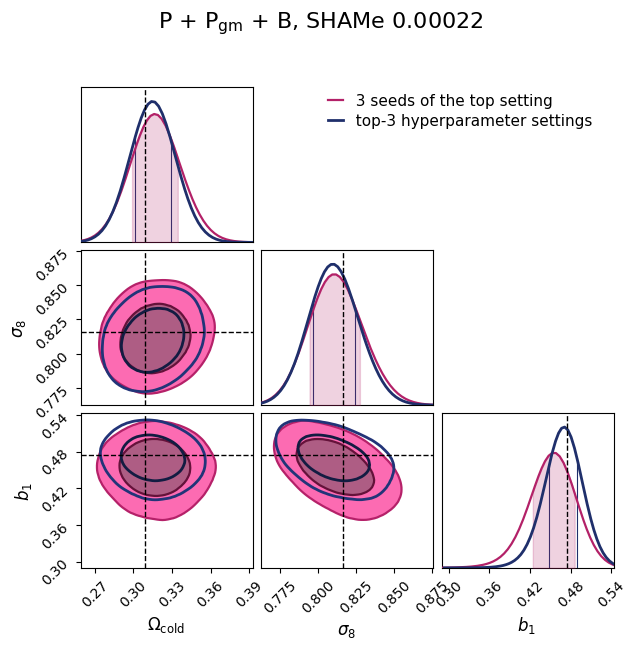

  3 seeds bias/σ: omega_cold=+0.52, sigma8_cold=-0.28, b1=-0.78 | σ: omega_cold=0.0159, sigma8_cold=0.0150, b1=0.0278
  top-3  bias/σ: omega_cold=+0.44, sigma8_cold=-0.39, b1=-0.25 | σ: omega_cold=0.0139, sigma8_cold=0.0141, b1=0.0221


In [6]:
import matplotlib.colors as mcolors
TAG_MOCK16 = "_nbar0.00022"
TRUTH16 = {k: float(v) for k, v in data_loader.load_params_ood("shame", TAG_MOCK16).items() if k in KEY3}
print("SHAMe truth:", {k: round(v, 3) for k, v in TRUTH16.items()})

def load_shame16(stats, masks, member):
    d = r16_dir(stats, masks, member)
    f = d / f"samples_test_shame_{stats}{masks}{TAG_MOCK16}_pred.npy"
    if not f.exists():
        return None
    s = np.load(f)
    s = s[:, 0, :] if s.ndim == 3 else s
    return to_key3(s, np.loadtxt(d / "param_names.txt", dtype=str))

for lab, (st, mk) in R16_COMBOS.items():
    ens = {e: [load_shame16(st, mk, m) for m in members] for e, members in R16_MEMBERS.items()}
    missing = {e: [m or "top" for m, a in zip(R16_MEMBERS[e], arrs) if a is None] for e, arrs in ens.items()}
    if any(missing.values()):
        print(f"{lab}: missing SHAMe samples {missing}"); continue
    mixes = [mix16(ens["3 seeds"]), mix16(ens["top-3 settings"])]
    colors = [R16_COLORS[lab], COLOR_TOP3]
    fig = plotter.plot_contours_inf(
        param_names=KEY3, idx_obs=0, theta_obs_true=None, inf_methods=["sbi"] * 2, tags_inf=["a", "b"],
        tags_test=["", ""], samples_list=[(m, KEY3) for m in mixes],
        labels=["3 seeds of the top setting", "top-3 hyperparameter settings"], colors=colors,
        linestyles=["-", "-"], shades=[True, False], bar_shades=[True, False], linewidths=[1.6, 2.0],
        unreparameterize=False, add_truth=True, truth_locations=[TRUTH16], truth_colors=["k"],
        figsize=(6.5, 6.5), fontsize_legend=11, title=f"{lab}, SHAMe {TAG_MOCK16[5:]}",
        legend_location=(0, 1), legend_loc="upper left", loc_legend=(0.35, 1.0), show=False,
    )
    if fig is None:
        continue
    diag = {ax.get_subplotspec().colspan.start: ax for ax in fig.axes
            if ax.get_subplotspec().rowspan.start == ax.get_subplotspec().colspan.start}
    for j in range(3):   # 68% interval of the top-3 mixture, lines stopping at its 1D curve
        ax = diag[j]
        curves = [l for l in ax.get_lines() if len(l.get_xdata()) > 10
                  and np.allclose(mcolors.to_rgba(l.get_color())[:3], mcolors.to_rgba(COLOR_TOP3)[:3])]
        for q in np.percentile(mixes[1][:, j], [16, 84]):
            y_top = np.interp(q, curves[0].get_xdata(), curves[0].get_ydata()) if curves else ax.get_ylim()[1]
            ax.vlines(q, 0, y_top, color=COLOR_TOP3, lw=0.8)
    fig.savefig(FIG_DIR / f"contours_shame_rand16_ens_{st}.pdf", bbox_inches="tight")
    plt.show()
    # (mean − truth)/σ and σ per mixture
    for e, mx in zip(("3 seeds", "top-3"), mixes):
        dev = [(mx[:, j].mean() - TRUTH16[k]) / mx[:, j].std() for j, k in enumerate(KEY3)]
        print(f"  {e:6s} bias/σ: " + ", ".join(f"{k}={v:+.2f}" for k, v in zip(KEY3, dev))
              + " | σ: " + ", ".join(f"{k}={mx[:, j].std():.4f}" for j, k in enumerate(KEY3)))


## 3. k_max grid: figure of bias on the SHAMe mock

The top sweep setting (`best-rand16`, seed 0, one network, not an ensemble) is retrained at each cut with the same hyperparameters. k_max^{P_gg} is fixed at 0.37. For P+P_gm+B we vary k_max^{P_gm} and k_max^B over the full K_CUTS grid (9 × 9). P+B and P+P_gm vary their single extra cut. Configs come from `code_auxiliary/make_kmax_grid_rand16.py`.

The figure of bias is FoB = $\sqrt{\Delta^T C^{-1} \Delta}$ in physical (Ω_c, σ8, b1). Δ is posterior mean − truth, and C is the posterior covariance, computed from unreparameterized samples. FoB is divided by $\sqrt{\chi^2_3(68.3\%)}$, so 1 is the 1σ contour in 3D, as in paper Fig 8. We use the SHAMe mock truth at each n̄. The phase-matched mean (our forward model on the SHAMe initial conditions, mean of 10 realizations) has the same truth. It isolates the forward-model prior-volume / network part of the bias from the SHAMe-vs-our-model mismatch, so SHAMe FoB well above matched FoB means model mismatch.

- **3a:** heatmap over (k_max^B, k_max^{P_gm}) for P+P_gm+B. Rows are SHAMe and phase-matched mean, columns are n̄. Grey cells are not done yet. The box marks the old fiducial (0.24, 0.24).
- **3b:** 1D slices, as in paper Fig 8 (9-10 / 11-15 paper notebooks): k_max^B with k_max^{P_gm} = 0.24, k_max^{P_gm} with k_max^B = 0.24, and joint k_max^B = k_max^{P_gm}. Shades are n̄ (light → dark = 1.1, 2.2, 5.4 × 10⁻⁴). Combos that don't depend on the swept cut are horizontal lines. P alone (kp0.37) is the thin line.

**Caveat:** each point is one network. Seed-to-seed scatter in FoB is not small, so judge trends, not single points. The point at the sweep cuts (kpgm0.24 / kb0.24) is the sweep trial itself. Every other point is a retrain with the same hyperparameters.

In [7]:
# §3 setup: k_max grid loaders and FoB
import matplotlib.colors as mcolors
from matplotlib.patches import Rectangle
from scipy.stats import chi2
import utils_inference
import plotter_figs

K_GRID = [0.11, 0.15, 0.18, 0.21, 0.24, 0.27, 0.31, 0.34, 0.37]
K_FID_OLD = 0.24
NBARS = ["0.00011", "0.00022", "0.00054"]
NBAR_LABS = {"0.00011": r"$\bar{n}=1.1\times10^{-4}$", "0.00022": r"$\bar{n}=2.2\times10^{-4}$",
             "0.00054": r"$\bar{n}=5.4\times10^{-4}$"}
MOCK_LABS = {"shame": "SHAMe", "matched": "phase-matched mean"}
FOB_PARAMS = ["omega_cold", "sigma8_cold", "b1"]
REF3 = float(np.sqrt(chi2.ppf(0.682689492137, 3)))
TAIL_K = "_p5_n10000_biasnoisenestv2_p9_n320000_noisefly_rp_bx32_ntrain10000_best-rand16"
K_COMBOS = {   # label: (stats tag, uses kpgm, uses kb, color)
    "P": ("pk", False, False, plotter_figs.COLORS_FID[0]),
    "P + P$_{\\rm gm}$": ("pk_pgm", True, False, plotter_figs.COLORS_FID[1]),
    "P + B": ("pk_bispec", False, True, plotter_figs.COLORS_FID[2]),
    "P + P$_{\\rm gm}$ + B": ("pk_pgm_bispec", True, True, plotter_figs.COLORS_FID[3]),
}
TRUTH_K = {nb: data_loader.load_params_ood("shame", f"_nbar{nb}") for nb in NBARS}
TRUTH_K = {nb: np.array([float(t[p]) for p in FOB_PARAMS]) for nb, t in TRUTH_K.items()}

def kgrid_tag(stats, kpgm=None, kb=None):
    return f"{stats}_kp0.37" + ("" if kpgm is None else f"_kpgm{kpgm:.2f}") + ("" if kb is None else f"_kb{kb:.2f}")

def kgrid_samples(stats, kpgm, kb, nbar, mock):
    sm = kgrid_tag(stats, kpgm, kb)
    d = DIR_SBI / f"sbi_muchisimocks_{sm}{TAIL_K}"
    if mock == "shame":
        f = d / f"samples_test_shame_{sm}_nbar{nbar}_pred.npy"
    else:
        f = d / (f"samples_test_muchisimocks_{sm}_shamematched{nbar}_p0_n10_biasshame{nbar}"
                 "_noisebest_p0_n1_noisematched_mean_pred.npy")
    if not f.exists():
        return None
    s = np.load(f)
    return (s[:, 0, :] if s.ndim == 3 else s), list(np.loadtxt(d / "param_names.txt", dtype=str))

_fob_cache = {}
def fob3(stats, kpgm, kb, nbar, mock="shame"):
    """FoB(Ω_c, σ8, b1) / sqrt(chi2_3(68%)); NaN if the test isn't done."""
    key = (stats, kpgm, kb, nbar, mock)
    if key not in _fob_cache:
        r = kgrid_samples(stats, kpgm, kb, nbar, mock)
        if r is None:
            _fob_cache[key] = np.nan
        else:
            mu, cov, names = utils_inference.physical_moments_from_samples(*r)
            idx = [list(names).index(p) for p in FOB_PARAMS]
            diff = mu[idx] - TRUTH_K[nbar]
            _fob_cache[key] = float(np.sqrt(diff @ np.linalg.solve(cov[np.ix_(idx, idx)], diff))) / REF3
    return _fob_cache[key]

def combo_fob(label, k_pgm, k_b, nbar, mock):
    """FoB for a combo at cuts (k_pgm, k_b); cuts a combo doesn't use are ignored."""
    stats, use_pgm, use_b, _ = K_COMBOS[label]
    return fob3(stats, k_pgm if use_pgm else None, k_b if use_b else None, nbar, mock)

grid_fob = {(mock, nb): np.array([[combo_fob("P + P$_{\\rm gm}$ + B", kp, kb, nb, mock) for kb in K_GRID]
                                  for kp in K_GRID]) for mock in MOCK_LABS for nb in NBARS}
for (mock, nb), g in grid_fob.items():
    print(f"P+Pgm+B {MOCK_LABS[mock]:20s} nbar {nb}: {np.isfinite(g).sum()}/{g.size} grid points done")

P+Pgm+B SHAMe                nbar 0.00011: 46/81 grid points done
P+Pgm+B SHAMe                nbar 0.00022: 46/81 grid points done
P+Pgm+B SHAMe                nbar 0.00054: 46/81 grid points done
P+Pgm+B phase-matched mean   nbar 0.00011: 46/81 grid points done
P+Pgm+B phase-matched mean   nbar 0.00022: 45/81 grid points done
P+Pgm+B phase-matched mean   nbar 0.00054: 43/81 grid points done


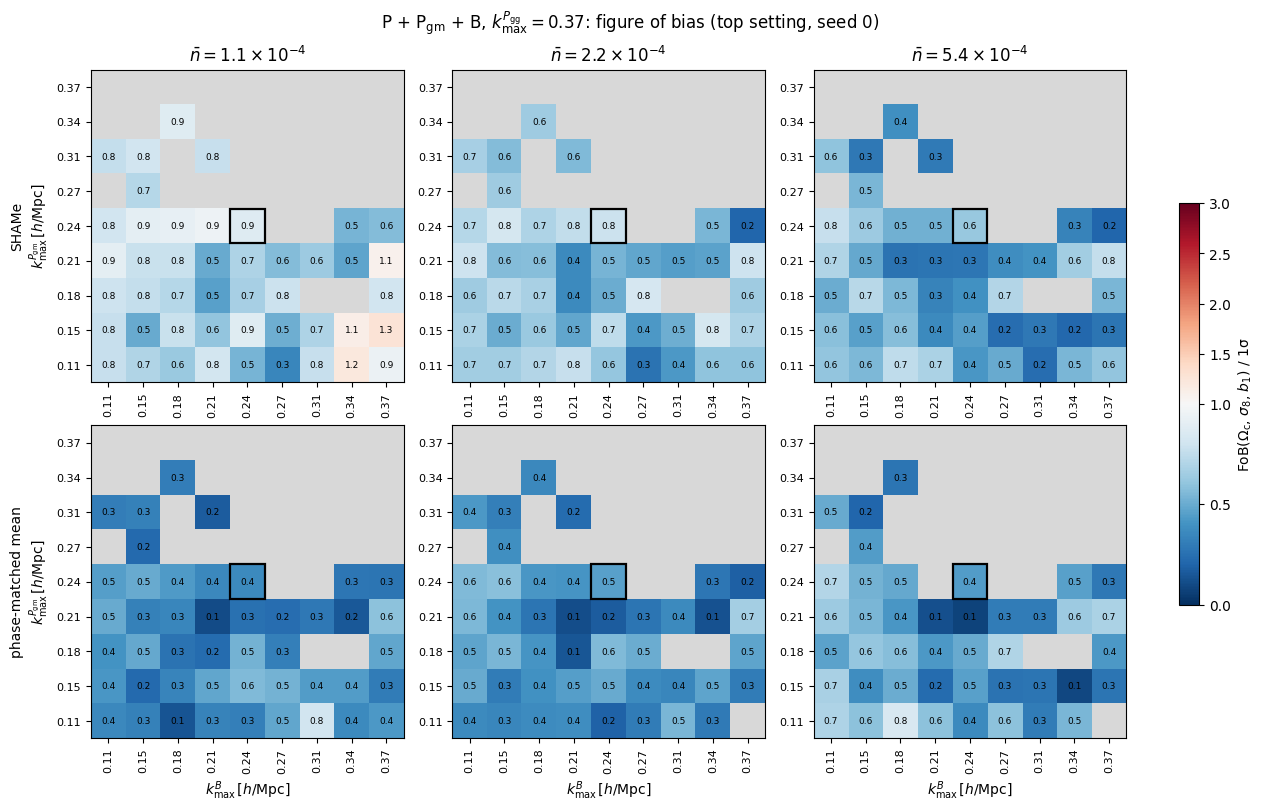

In [8]:
# 3a. P+P_gm+B FoB over the (k_max^B, k_max^{P_gm}) grid
norm = mcolors.TwoSlopeNorm(vmin=0, vcenter=1, vmax=3)
cmap = plt.get_cmap("RdBu_r").copy()
cmap.set_bad("0.85")
fig, axes = plt.subplots(len(MOCK_LABS), len(NBARS), figsize=(4.2 * len(NBARS), 4.0 * len(MOCK_LABS)),
                         squeeze=False, constrained_layout=True)
i_fid = K_GRID.index(K_FID_OLD)
for r, mock in enumerate(MOCK_LABS):
    for c, nb in enumerate(NBARS):
        ax, g = axes[r, c], grid_fob[(mock, nb)]
        im = ax.imshow(np.ma.masked_invalid(g), origin="lower", cmap=cmap, norm=norm, aspect="equal")
        for i in range(len(K_GRID)):
            for j in range(len(K_GRID)):
                if np.isfinite(g[i, j]):
                    ax.text(j, i, f"{g[i, j]:.1f}", ha="center", va="center", fontsize=6.5,
                            color="w" if abs(g[i, j] - 1) > 1.2 else "k")
        ax.add_patch(Rectangle((i_fid - 0.5, i_fid - 0.5), 1, 1, fill=False, ec="k", lw=1.6))
        ax.set_xticks(range(len(K_GRID)), [f"{k:.2f}" for k in K_GRID], rotation=90, fontsize=8)
        ax.set_yticks(range(len(K_GRID)), [f"{k:.2f}" for k in K_GRID], fontsize=8)
        if r == len(MOCK_LABS) - 1:
            ax.set_xlabel(r"$k_{\rm max}^{B}\,[h/{\rm Mpc}]$")
        if c == 0:
            ax.set_ylabel(f"{MOCK_LABS[mock]}\n" + r"$k_{\rm max}^{P_{\rm gm}}\,[h/{\rm Mpc}]$")
        if r == 0:
            ax.set_title(NBAR_LABS[nb])
fig.colorbar(im, ax=axes, shrink=0.6, label=r"FoB($\Omega_{\rm c}$, $\sigma_8$, $b_1$) / 1σ")
fig.suptitle(r"P + P$_{\rm gm}$ + B, $k_{\rm max}^{P_{\rm gg}}=0.37$: figure of bias (top setting, seed 0)")
fig.savefig(FIG_DIR / "kmax_grid_fob_pk_pgm_bispec.pdf", bbox_inches="tight")
plt.show()

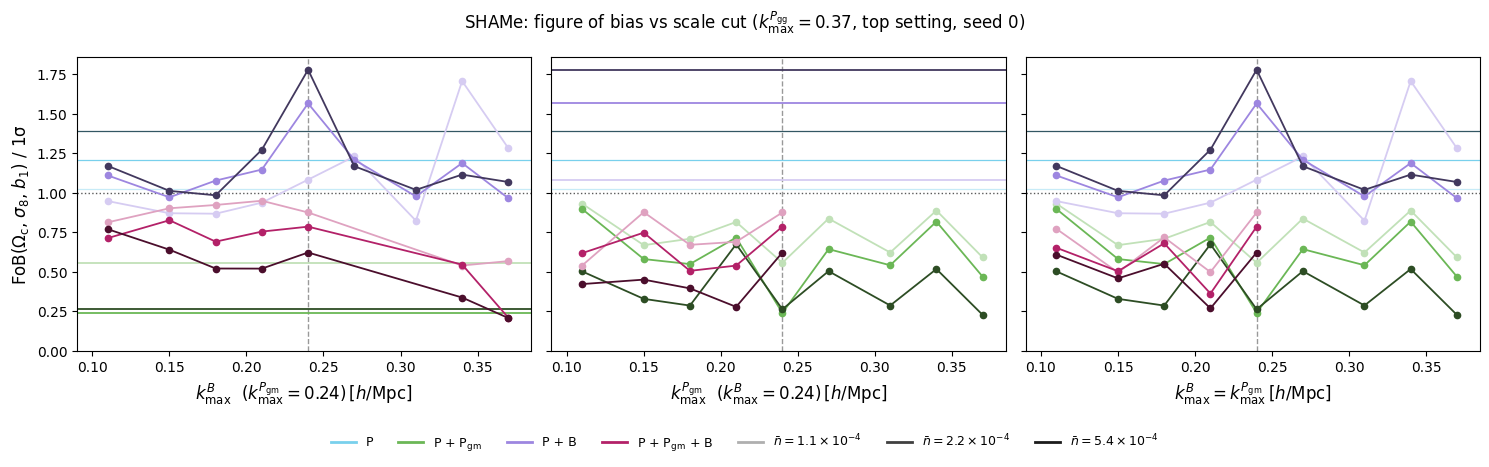

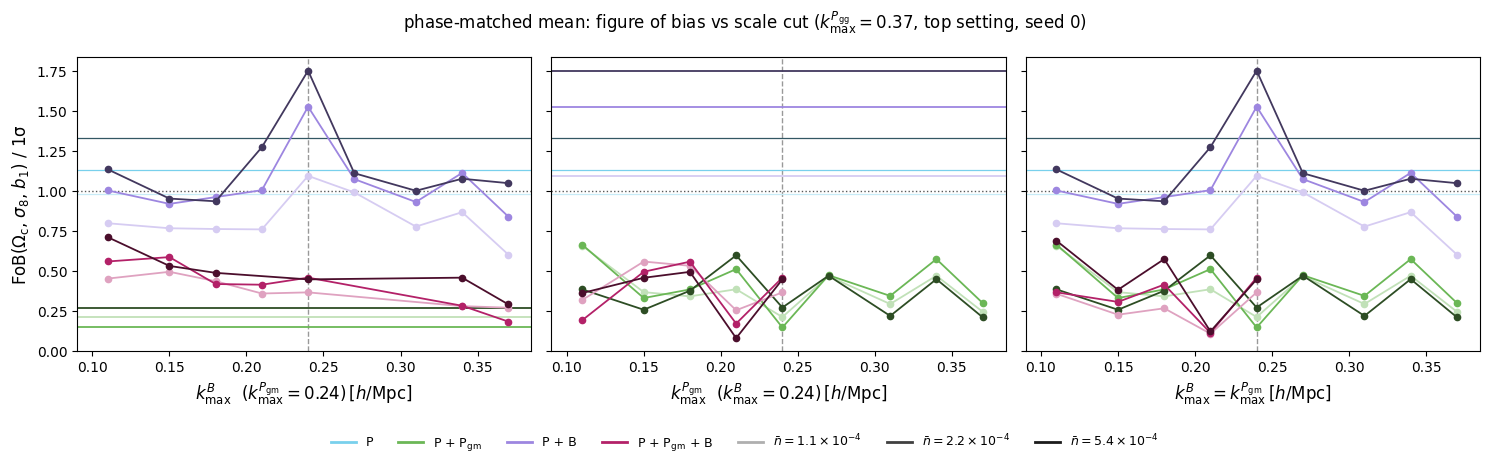

In [9]:
# 3b. 1D slices (paper Fig 8 layout): FoB vs one cut, the other fixed at the old fiducial 0.24
SLICES = [   # (x label, function k -> (k_pgm, k_b) for the swept cut, which combos vary along it)
    (r"$k_{\rm max}^{B}$  ($k_{\rm max}^{P_{\rm gm}}=0.24$)", lambda k: (K_FID_OLD, k), {"P + B", "P + P$_{\\rm gm}$ + B"}),
    (r"$k_{\rm max}^{P_{\rm gm}}$  ($k_{\rm max}^{B}=0.24$)", lambda k: (k, K_FID_OLD), {"P + P$_{\\rm gm}$", "P + P$_{\\rm gm}$ + B"}),
    (r"$k_{\rm max}^{B} = k_{\rm max}^{P_{\rm gm}}$", lambda k: (k, k), {"P + B", "P + P$_{\\rm gm}$", "P + P$_{\\rm gm}$ + B"}),
]

def plot_kmax_slices(mock):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
    for ax, (xlab, cuts, varying) in zip(axes, SLICES):
        for lab, (_, _, _, color) in K_COMBOS.items():
            shades = plotter_figs._nbar_shades(color)
            for j, nb in enumerate(NBARS):
                lab_j = lab if nb == "0.00022" else None
                if lab in varying:
                    y = np.array([combo_fob(lab, *cuts(k), nb, mock) for k in K_GRID])
                    ok = np.isfinite(y)
                    ax.plot(np.array(K_GRID)[ok], y[ok], "-o", color=shades[j], lw=1.3, ms=4.5, label=lab_j, zorder=3)
                else:   # independent of the swept cut: value at the old fiducial
                    v = combo_fob(lab, K_FID_OLD, K_FID_OLD, nb, mock)
                    if np.isfinite(v):
                        ax.axhline(v, color=shades[j], lw=0.9 if lab == "P" else 1.3, label=lab_j, zorder=2)
        ax.axhline(1.0, color="0.35", ls=":", lw=1.0, zorder=0)
        ax.axvline(K_FID_OLD, color="0.6", ls="--", lw=1.0, zorder=0)
        ax.set_xlim(0.09, 0.385)
        ax.set_xlabel(xlab + r"$\,[h/{\rm Mpc}]$", fontsize=12)
    axes[0].set_ylabel(r"FoB($\Omega_{\rm c}$, $\sigma_8$, $b_1$) / 1σ", fontsize=12)
    axes[0].set_ylim(bottom=0)
    h_stat = [Line2D([0], [0], color=c, lw=2) for (_, _, _, c) in K_COMBOS.values()]
    grey = plotter_figs._nbar_shades("0.25")
    h_nbar = [Line2D([0], [0], color=grey[j], lw=2) for j in range(3)]
    fig.legend(h_stat + h_nbar, list(K_COMBOS) + [NBAR_LABS[n] for n in NBARS], fontsize=9, frameon=False,
               loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=7)
    fig.suptitle(f"{MOCK_LABS[mock]}: figure of bias vs scale cut ($k_{{\\rm max}}^{{P_{{\\rm gg}}}}=0.37$, top setting, seed 0)")
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"kmax_slices_fob_{mock}.pdf", bbox_inches="tight")
    plt.show()

for mock in MOCK_LABS:
    plot_kmax_slices(mock)

In [10]:
# numbers behind 3b at the fiducial n̄: FoB per combo along each slice (NaN = not done)
SLICE_NAMES = dict(zip([sl[0] for sl in SLICES], ["kb (kpgm=0.24)", "kpgm (kb=0.24)", "kb = kpgm"]))
COMBO_PLAIN = dict(zip(K_COMBOS, ["P", "P+Pgm", "P+B", "P+Pgm+B"]))
rows = []
for xlab, cuts, varying in SLICES:
    for lab in varying:
        for mock in MOCK_LABS:
            rows.append({"slice": SLICE_NAMES[xlab], "combo": COMBO_PLAIN[lab],
                         "mock": mock, **{k: combo_fob(lab, *cuts(k), "0.00022", mock) for k in K_GRID}})
pd.DataFrame(rows).set_index(["slice", "combo", "mock"]).T.round(2).rename_axis("k_max")

slice kb (kpgm=0.24)                       kpgm (kb=0.24)                \
combo        P+Pgm+B           P+B                P+Pgm+B         P+Pgm   
mock           shame matched shame matched          shame matched shame   
k_max                                                                     
0.11            0.71    0.56  1.11    1.00           0.62    0.19  0.90   
0.15            0.82    0.58  0.97    0.92           0.75    0.49  0.58   
0.18            0.69    0.42  1.08    0.96           0.50    0.56  0.55   
0.21            0.75    0.41  1.15    1.00           0.54    0.17  0.72   
0.24            0.78    0.46  1.56    1.53           0.78    0.46  0.24   
0.27             NaN     NaN  1.21    1.07            NaN     NaN  0.64   
0.31             NaN     NaN  0.98    0.93            NaN     NaN  0.54   
0.34            0.54    0.28  1.19    1.11            NaN     NaN  0.82   
0.37            0.21    0.18  0.96    0.84            NaN     NaN  0.47   

slice         kb = kpgm                                        
combo               P+B         P+Pgm+B         P+Pgm          
mock  matched     shame matched   shame matched shame matched  
k_max                                                          
0.11     0.66      1.11    1.00    0.65    0.36  0.90    0.66  
0.15     0.33      0.97    0.92    0.50    0.30  0.58    0.33  
0.18     0.38      1.08    0.96    0.68    0.41  0.55    0.38  
0.21     0.51      1.15    1.00    0.36    0.11  0.72    0.51  
0.24     0.14      1.56    1.53    0.78    0.46  0.24    0.14  
0.27     0.47      1.21    1.07     NaN     NaN  0.64    0.47  
0.31     0.34      0.98    0.93     NaN     NaN  0.54    0.34  
0.34     0.57      1.19    1.11     NaN     NaN  0.82    0.57  
0.37     0.30      0.96    0.84     NaN     NaN  0.47    0.30

## 4. Prior leakage: posterior mass outside the physical prior box

The flow samples in the reparameterized space (`_rp`: σ8·b1, σ8²·b2, σ8²·bs2, σ8·bl and the same for the noise amplitudes). The training draws fill a wedge inside the bounding box of that space, since each product's range depends on σ8. In v1 the rejection step tested the bounding box, so 17–37% of coverage samples ended up outside the physical prior (`generate_params.BOUNDS`) after undoing the reparameterization (2026-11-15 audit).

In v2 the prior is `sbi_model.PhysicalSupportBoxUniform`: same box for training, but its support check (used for rejection) tests the physical bounds. Two checks:
- **Samples outside the box** after un-reparameterizing: should be 0 up to float32 round-off at the edges (the support check runs in float32), i.e. any excursion should be ~1e-7 of the box width. Confirms the fix is live in every model.
- **Rejection acceptance** per observation: the fraction of flow draws inside the physical box, i.e. how much posterior mass the flow puts outside the prior before truncation. Low acceptance is fine statistically (the truncated posterior is the right one) but flags rows where the flow leaks a lot, and costs sampling time.

Models: the 5 ensemble candidates on the coverage `inner500` rows (top setting seed 0 runs the full 1000; its inner500 rows are used), and the top setting seed 0 on SHAMe and the phase-matched mocks at the 3 densities. Unfinished rows are skipped.

In [11]:
# §4 setup + leakage table
import generate_params as genp
import utils_inference

LK_COMBOS = {"P": ("pk", "_kp0.37"), "P + P$_{\\rm gm}$": ("pk_pgm", "_kp0.37_kpgm0.24"),
             "P + B": ("pk_bispec", "_kp0.37_kb0.24"), "P + P$_{\\rm gm}$ + B": ("pk_pgm_bispec", "_kp0.37_kpgm0.24_kb0.24")}
LK_MEMBERS = ["", "_seed1", "_seed2", "_nbest1", "_nbest2"]
LK_NBARS = ["0.00011", "0.00022", "0.00054"]
LK_TAG_COV = "_coveragev2_p5_n1000_biasnoisecoveragev2_p9_n1000_noisefly"
LK_SUB = "inner500"
LK_BOUNDS = {**genp.BOUNDS["cosmo"], **genp.BOUNDS["bias"], **genp.BOUNDS["Anoisemult"]}
lk_idxs = np.load(REPO_ROOT / "data" / "params" / f"idxs_obs_coveragev2_p5_n1000_{LK_SUB}.npy")
_lk_cos = pd.read_csv(REPO_ROOT / "data" / "params" / "params_lh_coveragev2_p5_n1000.txt", index_col=0)
lk_truth_s8 = _lk_cos.loc[lk_idxs, "sigma8_cold"].to_numpy()

def lk_dir(stats, masks, member):
    return DIR_SBI / f"sbi_muchisimocks_{stats}{masks}_p5_n10000_biasnoisenestv2_p9_n320000_noisefly_rp_bx32_ntrain10000_best-rand16{member}"

def lk_files(stats, masks, member, test):
    """(samples path, acceptance path or None, obs index subset or None) for a test; None if not on disk."""
    d = lk_dir(stats, masks, member)
    if test == "coverage":
        base = f"samples_test_muchisimocks_{stats}{masks}{LK_TAG_COV}" + ("" if member == "" else f"_{LK_SUB}")
        sub = lk_idxs if member == "" else None
    elif test.startswith("shame"):
        base, sub = f"samples_test_shame_{stats}{masks}_nbar{test[len('shame'):]}", None
    else:   # matched<nbar>
        nb_ = test[len("matched"):]
        base = (f"samples_test_muchisimocks_{stats}{masks}_shamematched{nb_}_p0_n10"
                f"_biasshame{nb_}_noisebest_p0_n1_noisematched")
        sub = None
    for suffix in ("_pred.npy", "_pred_inprogress.npy"):
        if (d / (base + suffix)).exists():
            acc = d / (base + "_acceptance.npy")
            return d / (base + suffix), (acc if acc.exists() else None), sub
    return None

def lk_outside(stats, masks, member, test, chunk=50):
    """Per-obs fraction of samples outside the box (any param), per-param fractions over all samples,
    per-obs acceptance; obs with unfinished (NaN) samples dropped. None if missing."""
    got = lk_files(stats, masks, member, test)
    if got is None:
        return None
    fn, fn_acc, sub = got
    d = lk_dir(stats, masks, member)
    names_rp = list(np.loadtxt(d / "param_names.txt", dtype=str))
    s = np.load(fn, mmap_mode="r")
    if s.ndim == 2:
        s = s[:, None, :]
    obs = np.arange(s.shape[1]) if sub is None else np.asarray(sub)
    acc = None
    if fn_acc is not None:
        a = np.atleast_1d(np.load(fn_acc))
        acc = a[obs] if a.size == s.shape[1] else None
    any_out, n_tot, n_out_par, keep, names, max_dist = [], 0, None, [], None, -np.inf
    for i0 in range(0, len(obs), chunk):
        x = np.asarray(s[:, obs[i0:i0 + chunk], :], dtype=np.float64)
        ok = np.isfinite(x).all(axis=(0, 2))
        if not ok.any():
            keep.append(ok); continue
        x, names = utils_inference.unreparameterize_theta(x[:, ok], names_rp, strict=False)
        names = list(names)
        lo = np.array([LK_BOUNDS[n][0] for n in names]); hi = np.array([LK_BOUNDS[n][1] for n in names])
        out = (x < lo) | (x > hi)                      # (n_samples, n_ok, n_params)
        # how far outside, in units of the box width (float32 round-off at the edges is ~1e-7)
        dist = np.maximum(lo - x, x - hi) / (hi - lo)
        max_dist = max(max_dist, float(np.nanmax(dist, initial=-np.inf)))
        any_out.append(out.any(axis=2).mean(axis=0))
        n_out_par = out.sum(axis=(0, 1)) if n_out_par is None else n_out_par + out.sum(axis=(0, 1))
        n_tot += out.shape[0] * out.shape[1]
        keep.append(ok)
    keep = np.concatenate(keep)
    if not any_out:
        return None
    return dict(any_out=np.concatenate(any_out), keep=keep, names=names,
                frac_par=n_out_par / n_tot, acc=None if acc is None else acc[keep], max_dist=max_dist,
                kind="done" if fn.name.endswith("_pred.npy") else "inprogress")

lk_res = {}
for lab, (st, mk) in LK_COMBOS.items():
    for m in LK_MEMBERS:
        lk_res[(lab, m, "coverage")] = lk_outside(st, mk, m, "coverage")
    for nb_ in LK_NBARS:
        for t in ("shame", "matched"):
            lk_res[(lab, "", f"{t}{nb_}")] = lk_outside(st, mk, "", f"{t}{nb_}")

rows = []
for (lab, m, test), r in lk_res.items():
    if r is None:
        continue
    row = {"combo": lab, "model": m.strip("_") or "top seed0", "test": test, "n_obs": len(r["any_out"]),
           "frac samples outside box": r["any_out"].mean(),
           "max dist outside / width": max(r["max_dist"], 0.0)}
    if r["acc"] is not None:
        a = r["acc"]
        row.update({"acc median": np.nanmedian(a), "acc 5%": np.nanpercentile(a, 5), "acc min": np.nanmin(a),
                    "rows acc<0.5": np.mean(a < 0.5)})
    rows.append(row)
df_leak = pd.DataFrame(rows).set_index(["combo", "model", "test"])
print(f"samples outside generate_params.BOUNDS: max fraction {df_leak['frac samples outside box'].max():.2e}, "
      f"furthest {df_leak['max dist outside / width'].max():.1e} of the box width")
print("acc = rejection acceptance per obs (fraction of flow draws inside the physical box)")
with pd.option_context("display.max_rows", 200, "display.width", 250):
    display(df_leak.style
            .format("{:.1e}", subset=["frac samples outside box", "max dist outside / width"])
            .format("{:.3f}", subset=["acc median", "acc 5%", "acc min", "rows acc<0.5"])
            .background_gradient(cmap="Reds_r", subset=["acc median", "acc 5%"], vmin=0, vmax=1))


samples outside generate_params.BOUNDS: max fraction 4.00e-07, furthest 9.5e-08 of the box width
acc = rejection acceptance per obs (fraction of flow draws inside the physical box)


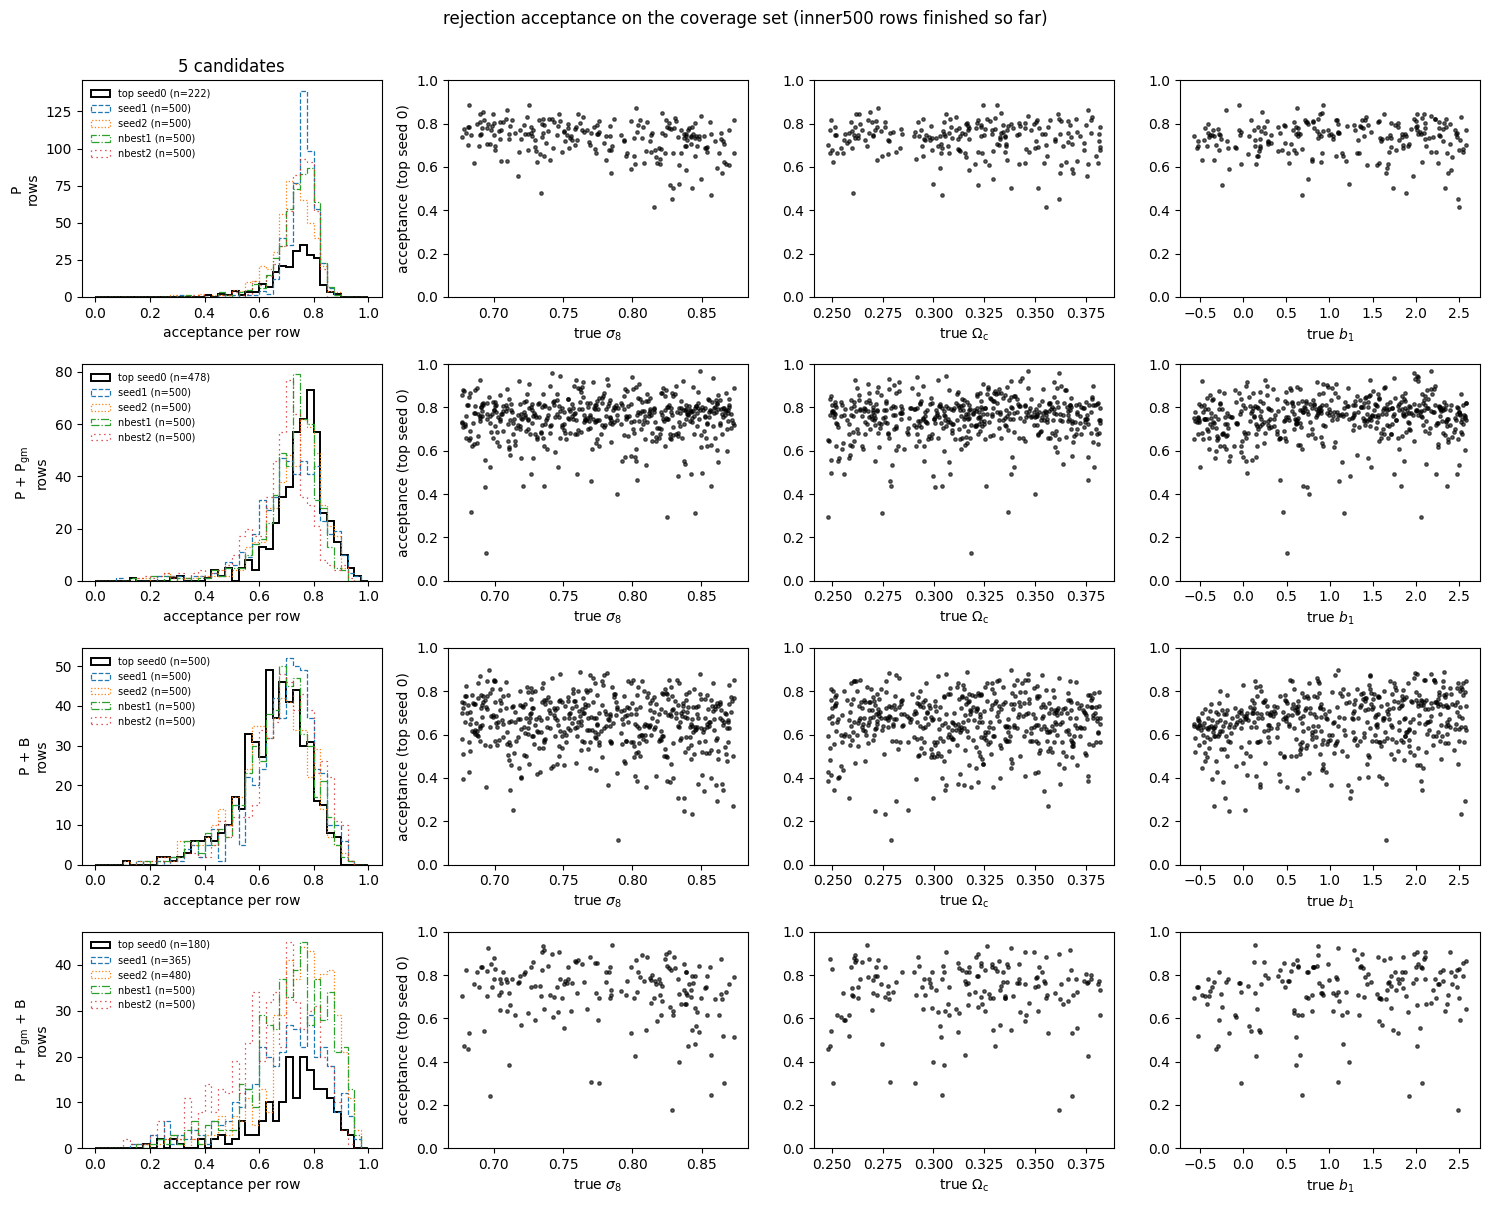

In [12]:
# 4b. Coverage rows: where is acceptance low? (rejection acceptance per row)
_lk_bia = pd.read_csv(REPO_ROOT / "data" / "params" / "params_lh_biasnoisecoveragev2_p9_n1000.txt", index_col=0)
lk_truth = {"sigma8_cold": lk_truth_s8, "omega_cold": _lk_cos.loc[lk_idxs, "omega_cold"].to_numpy(),
            "b1": _lk_bia.loc[lk_idxs, "b1"].to_numpy()}
LK_X = [("sigma8_cold", r"true $\sigma_8$"), ("omega_cold", r"true $\Omega_{\rm c}$"), ("b1", r"true $b_1$")]
fig, axes = plt.subplots(len(LK_COMBOS), 1 + len(LK_X), figsize=(15, 3.0 * len(LK_COMBOS)), squeeze=False)
for r_, lab in enumerate(LK_COMBOS):
    ax0 = axes[r_, 0]
    bins = np.linspace(0, 1, 41)
    for m, ls in zip(LK_MEMBERS, ["-", "--", ":", "-.", (0, (1, 3))]):
        rm = lk_res[(lab, m, "coverage")]
        if rm is not None and rm["acc"] is not None:
            ax0.hist(rm["acc"], bins=bins, histtype="step", ls=ls, lw=1.4 if m == "" else 0.9,
                     color="k" if m == "" else None, label=f"{m.strip('_') or 'top seed0'} (n={len(rm['acc'])})")
    ax0.set_xlabel("acceptance per row"); ax0.set_ylabel(f"{lab}\nrows"); ax0.legend(fontsize=7, frameon=False)
    res = lk_res[(lab, "", "coverage")]
    for c, (p, xl) in enumerate(LK_X, start=1):
        ax = axes[r_, c]
        if res is not None and res["acc"] is not None:
            ax.scatter(lk_truth[p][res["keep"]], res["acc"], s=6, alpha=0.6, color="k")
        ax.set_xlabel(xl); ax.set_ylim(0, 1)
        if c == 1:
            ax.set_ylabel("acceptance (top seed 0)")
axes[0, 0].set_title("5 candidates")
fig.suptitle(f"rejection acceptance on the coverage set ({LK_SUB} rows finished so far)", y=1.0)
fig.tight_layout()
fig.savefig(FIG_DIR / "prior_acceptance_coverage_rand16.pdf", bbox_inches="tight")
plt.show()


**Findings (2026-11-20, partial coverage).** The v1 leakage is gone: in every model and test the fraction of samples outside the physical box is ≤ 4×10⁻⁷, all within ~10⁻⁷ of the box width (float32 round-off at the edges), vs 17–37% in v1. Rejection acceptance on the coverage rows has a median of 0.66–0.77, with a tail to ~0.1; the tail is widest for P + B and P + P$_{\rm gm}$ + B (8–18% of rows below 0.5). Low-acceptance rows don't line up with the true σ8, Ω_c or b1 edges, so it's not one corner of the prior. On SHAMe and the phase-matched mocks acceptance is 0.81–0.98. Nothing here separates the ensemble candidates. Acceptance only costs sampling time; the truncated posterior is the correct one.

## 5. Paper Fig 7 with the top model only: SHAMe vs phase-matched mock across n̄

Paper Fig 7 (`plotter_figs.plot_fig7_noise_impact_contours_nbars`) for the top setting, seed 0 alone (`k_members=1`), P + P$_{\rm gm}$ + B at the fiducial cuts. Filled: SHAMe at the 3 densities. Unfilled, orange shades matched by n̄: the phase-matched mock (SHAMe ICs + our forward model, mean of 10 noise realizations) at the same densities. The two share the truth at each n̄, so the offset between same-shade filled and unfilled contours is the model-mismatch part of the SHAMe bias. The paper version uses the ensemble (needs the other members' matched tests).

SAVE_FIGURES: True
FIG_DIR: /home/kstoreyf/muchisimocks/figures/2026-11-19_v2_checks
FIG_DIR_LATEST: /home/kstoreyf/muchisimocks/figures/2026-11-19_v2_checks
OVERWRITE_FIGURES: True
FIG_EXT: pdf
Found 6/6 (K=1 ensemble).


Saved: /home/kstoreyf/muchisimocks/figures/2026-11-19_v2_checks/fig7_shame_vs_matched_nbars_topmodel.pdf


Saved: /home/kstoreyf/muchisimocks/figures/2026-11-19_v2_checks/fig7_shame_vs_matched_nbars_topmodel.pdf


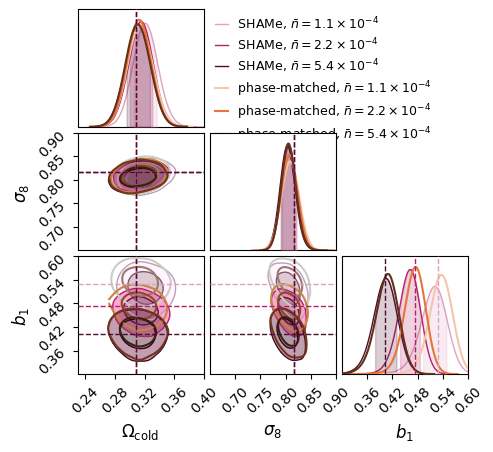

In [13]:
# §5: Fig 7, top model only
import plotter_figs as pf
pf.configure_figures(save=True, fig_dir=FIG_DIR, fig_dir_latest=FIG_DIR, ext="pdf")
pf.plot_fig7_noise_impact_contours_nbars(save_name="fig7_shame_vs_matched_nbars_topmodel", k_members=1)
